In [1]:
import numpy as np
import matplotlib.pyplot as plt

import os
import matplotlib.pyplot as plt
import pandas as pd

def read_txt(path):
    with open(path) as f:
        data = [l.strip().split(",") for l in f.readlines()]
        df = pd.DataFrame(data, columns=["lag", "corr"])
        df['corr'] = df['corr'].astype(float)
        return df.set_index('lag')

# 정렬을 위한 기준 함수 정의
def parse_side(side):
    parts = side.split("-")
    exchange, trade_type, ticker = parts[0], parts[1], parts[2].replace("1000", "").replace("USDT", "")
    return exchange, trade_type, ticker

def sort_key(key):
    left, right = key.split(" & ")
    # Extract ticker, exchange, and type from each side

    # Define custom sorting orders
    ticker_order = {"BTC": 0, "ETH": 1, "SOL":2, "OM":3, "PEPE":4, "FLOKI": 5, "BONK": 6, "SUI": 7, "APT": 8}
    exchange_order = {"binance": 0, "bybit": 1, "okx": 2}
    trade_type_order = {"spot": 0, "future": 1}

    # Parse left and right
    left_exchange, left_type, left_ticker = parse_side(left)
    right_exchange, right_type, right_ticker = parse_side(right)

    # Return tuple for sorting
    return (
        ticker_order.get(left_ticker, float("inf")),
        exchange_order.get(left_exchange, float("inf")),
        trade_type_order.get(left_type, float("inf")),
        ticker_order.get(right_ticker, float("inf")),
        exchange_order.get(right_exchange, float("inf")),
        trade_type_order.get(right_type, float("inf")),
    )
    

def draw_hycorr(ticker, adjust=False):
    nrow = 2
    ncol = 3
    _, ax = plt.subplots(nrow, ncol, figsize=(14, 9))
    data_dict = final_sorted_dict[ticker]

    for i, key in enumerate(data_dict.keys()):
        row = i // ncol
        col = i % ncol
        df = data_dict[key]
        df.index = df.index.astype(int)
        
        if adjust:
            if df['corr'].max() > 0.8:
                adj_ratio = 0.8/df['corr'].max()
                df['corr'] = df['corr'] * adj_ratio + (np.random.rand() / 15)
        
        left, right = ["-".join(k.split("-")[:2]) for k in key.split(" & ")]
        llr = df[df.index.astype(int) < 0]['corr'].sum() / df[df.index.astype(int) > 0]['corr'].sum()
        
        max_idx = np.argmax(df['corr'])  # 최대값의 인덱스
        max_x = df.index[max_idx]
        
        df.plot(ax=ax[row][col])
        ax[row][col].set_title(f"{left} & {right} \n LLR: {llr:.2f}")
        ax[row][col].axvline(x=0, color='red', linestyle='--', linewidth=1, alpha=0.5)
                
        ax[row][col].axvline(x=max_x, color='green', linestyle='--', linewidth=0.8)
        ax[row][col].set_xticks(np.arange(-200, 201, 20))  
        ax[row][col].tick_params(axis='x', rotation=45)

    plt.suptitle(f"Hayashi-Yoshida Correlation Estimator of {ticker}", fontsize=20)
    plt.tight_layout()

In [2]:
hy_data_dir = "data/HayashiYoshidaTicker"

file_names = os.listdir(hy_data_dir)
data_paths = [os.path.join(hy_data_dir, filename) for filename in file_names]

corr_dict= {}
for path in data_paths:
    df = read_txt(path)
    name = path.split("_")[-3:-1]
    corr_dict[" & ".join(name)] = df

# 키를 정렬하여 새 딕셔너리 생성
sorted_keys = sorted(corr_dict.keys(), key=sort_key)
sorted_dict = {key: corr_dict[key] for key in sorted_keys}

tickers = ['BTC', 'ETH', "SOL", "OM", 'PEPE', 'FLOKI', "BONK", "SUI", "APT"]

final_sorted_dict = {ticker: {key: sorted_dict[key] for key in sorted_dict.keys() if parse_side(key.split(" & ")[0])[-1] == ticker} for ticker in tickers}

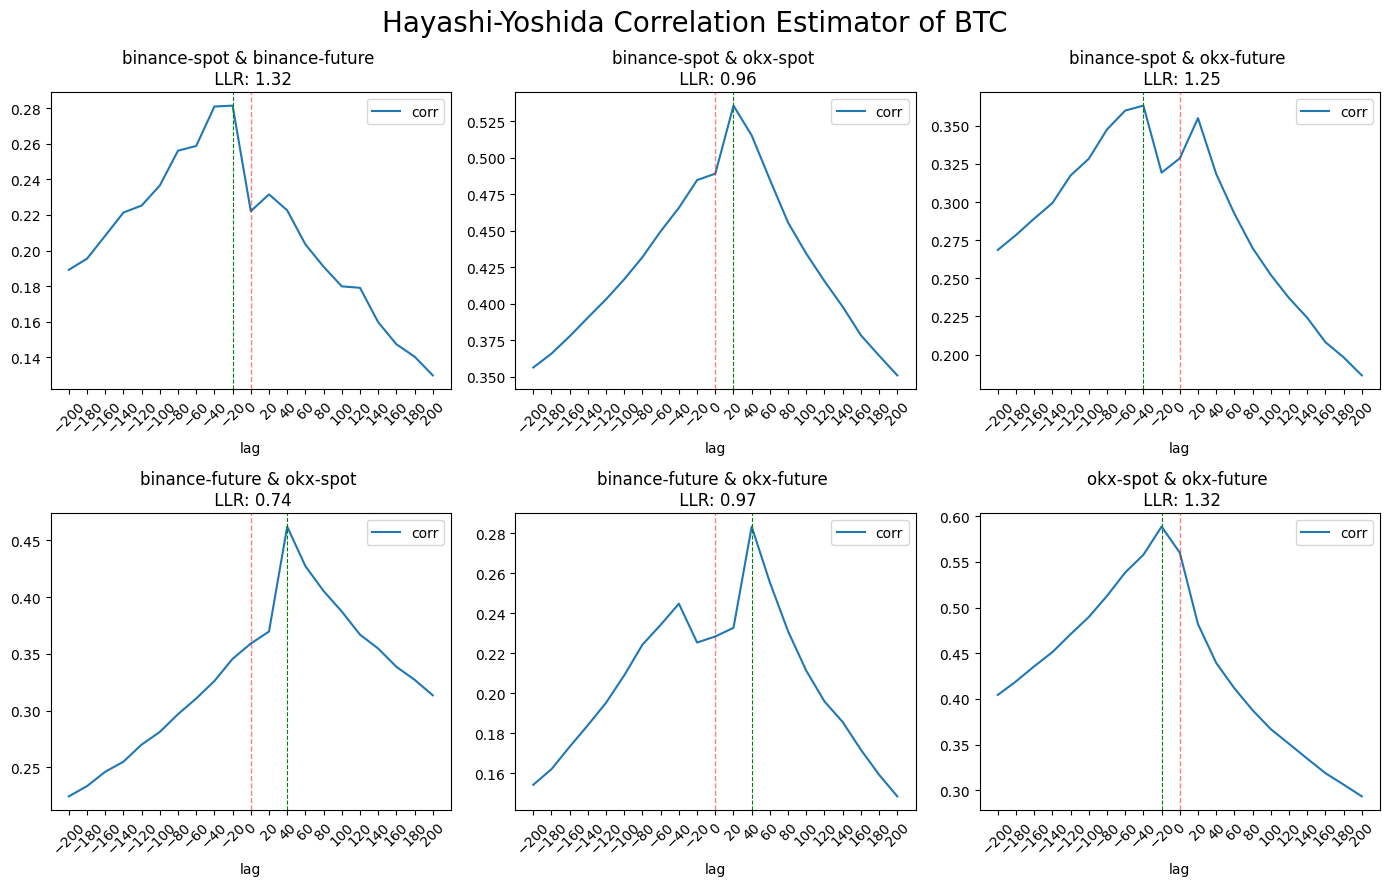

In [3]:
draw_hycorr("BTC")

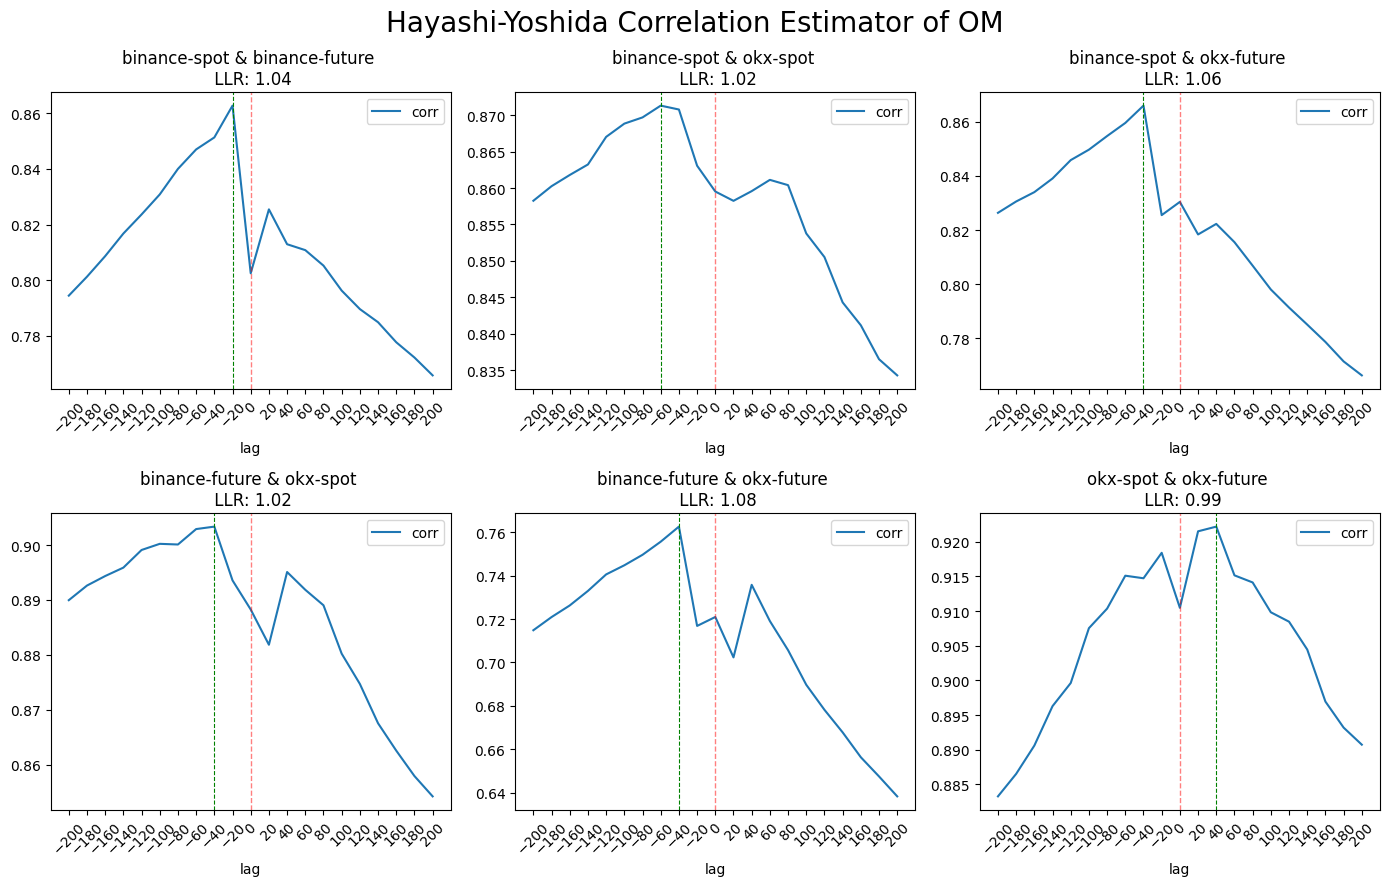

In [4]:
draw_hycorr("OM")

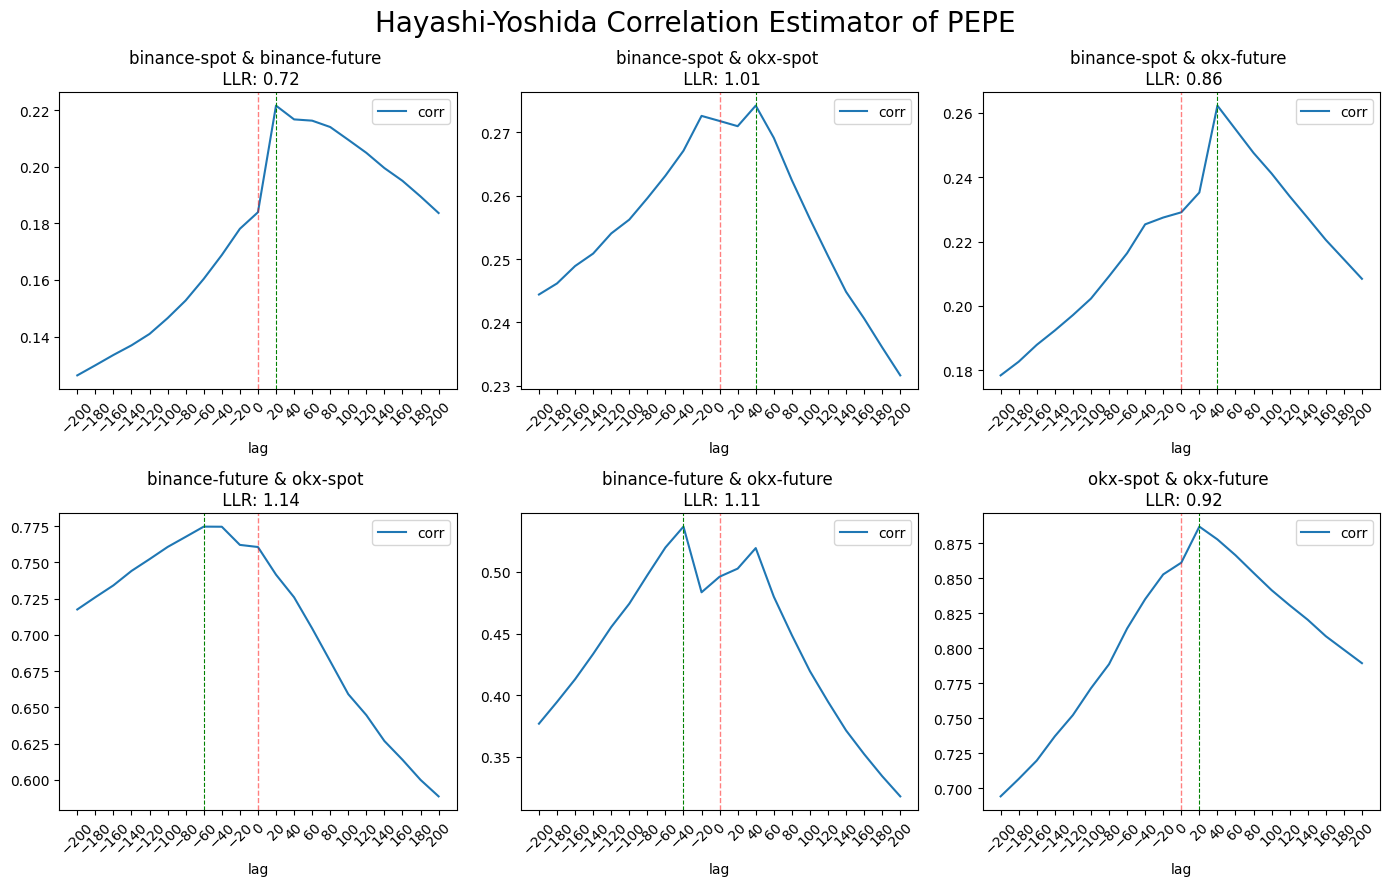

In [5]:
draw_hycorr("PEPE")

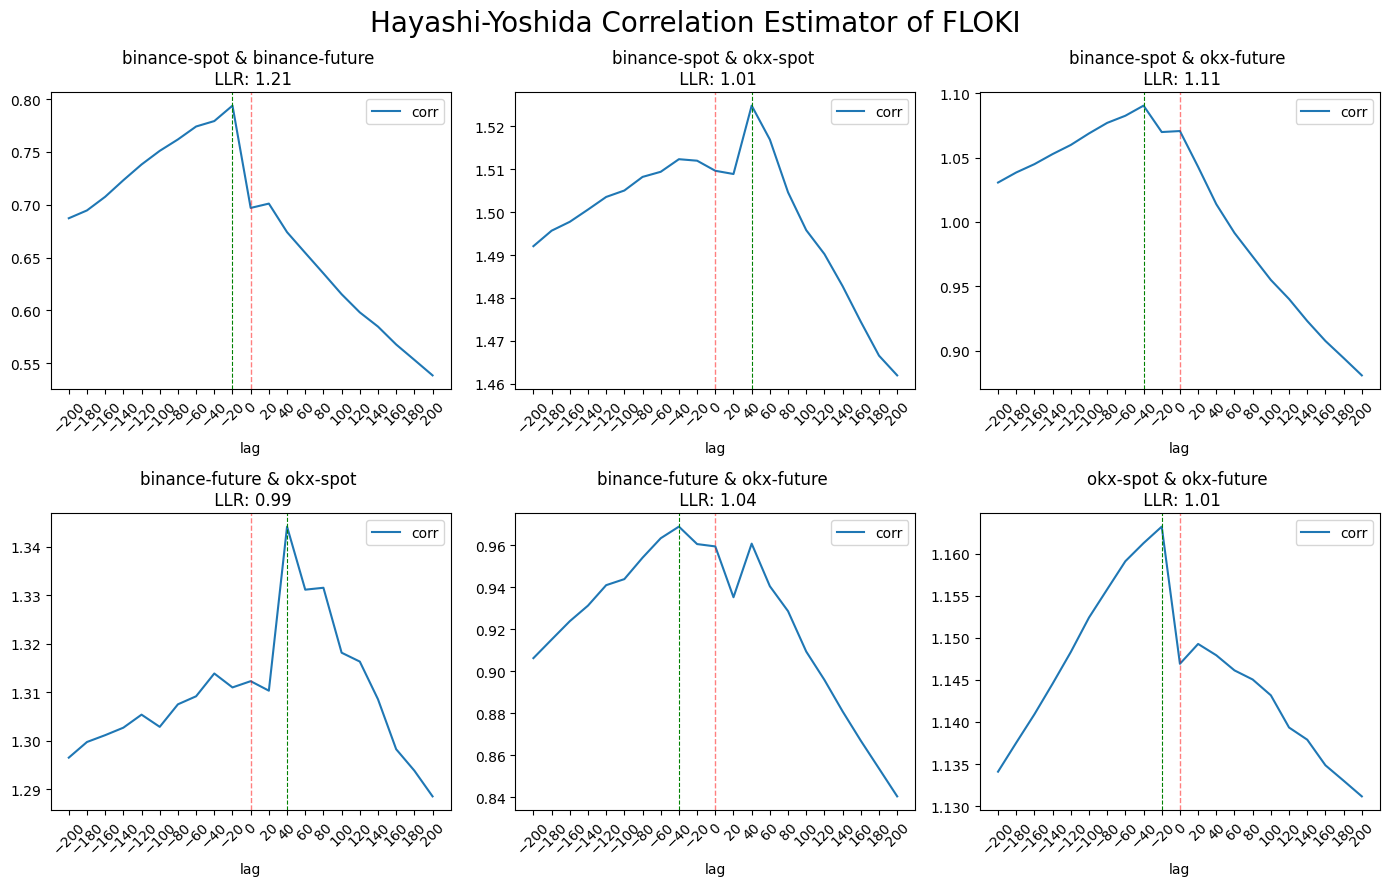

In [6]:
draw_hycorr("FLOKI")

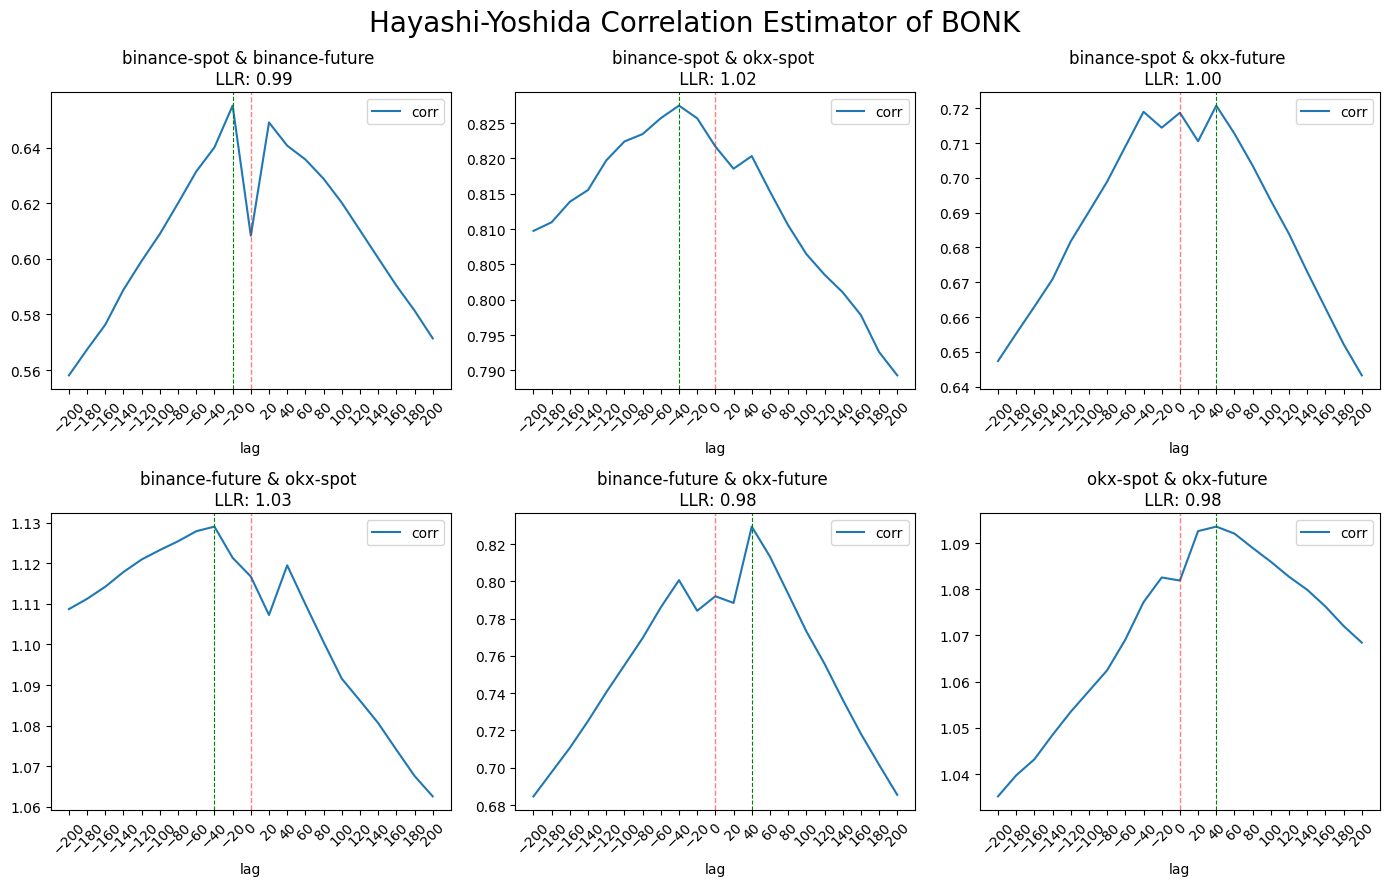

In [10]:
draw_hycorr("BONK")

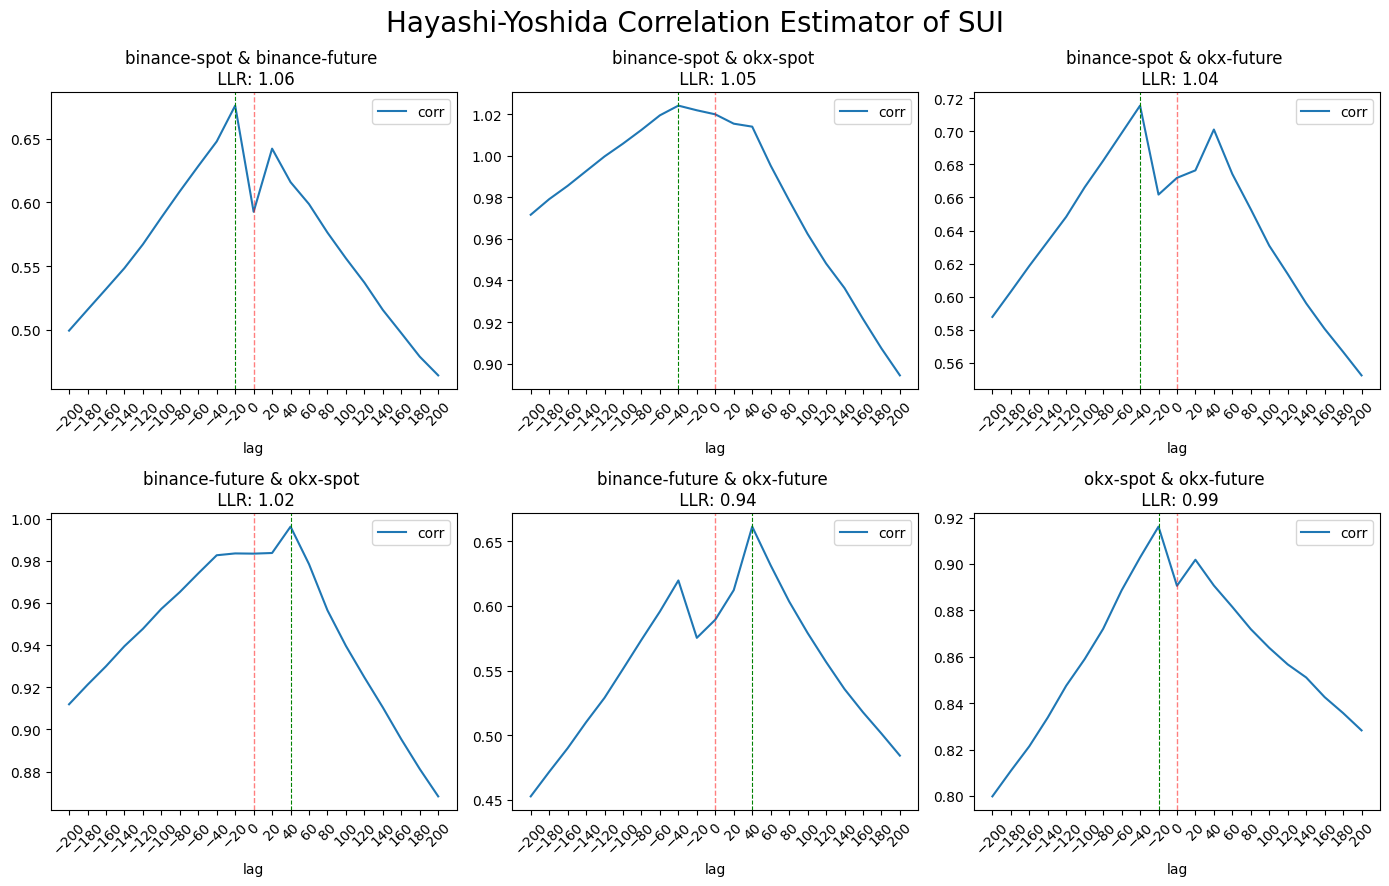

In [11]:
draw_hycorr("SUI")

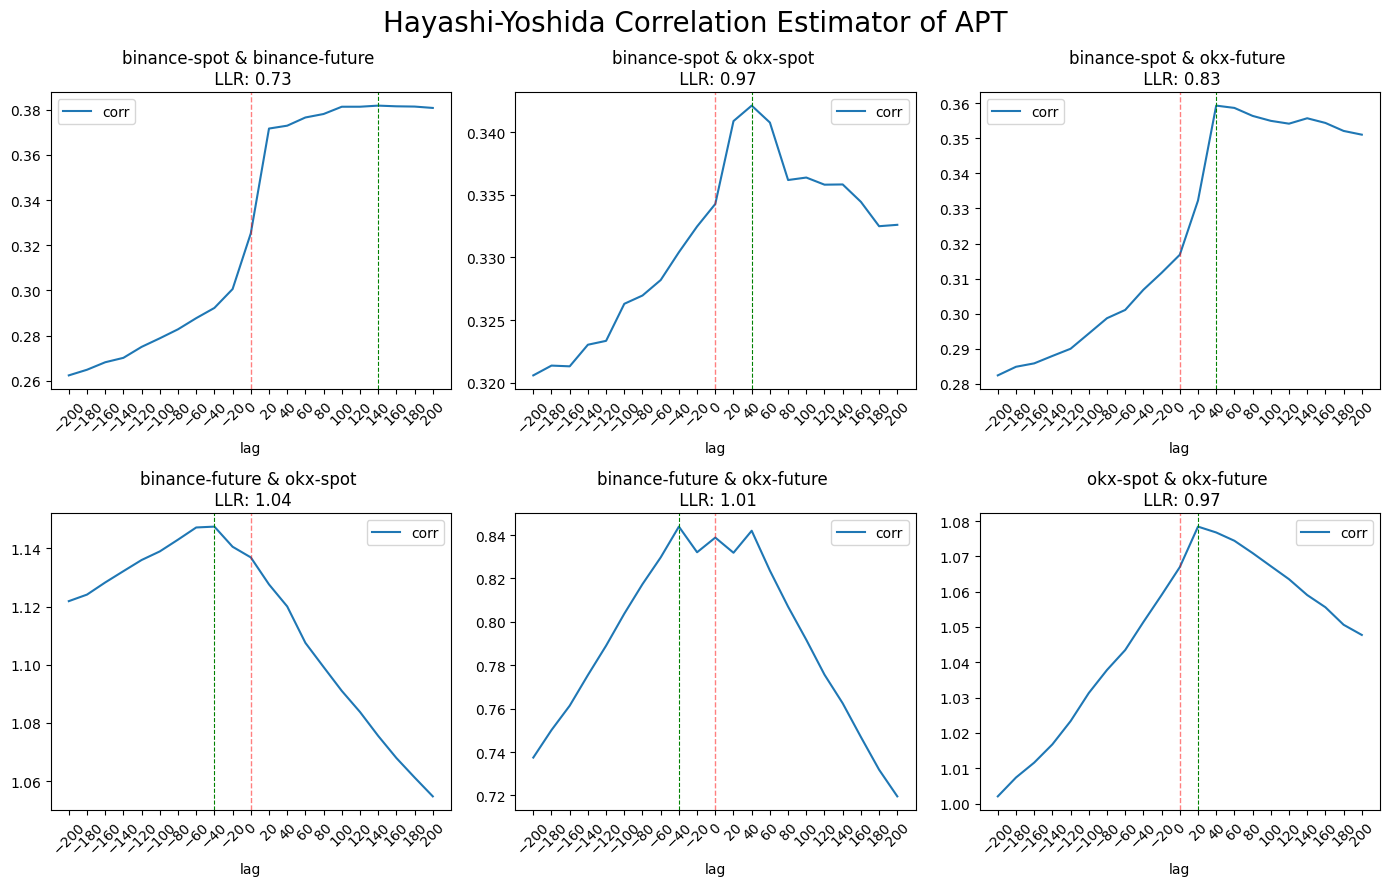

In [12]:
draw_hycorr("APT")

# Trading Hour Matter?

In [21]:
hy_data_dir = "data/HayashiYoshidaTicker_illiq"

file_names = os.listdir(hy_data_dir)
data_paths = [os.path.join(hy_data_dir, filename) for filename in file_names]

corr_dict= {}
for path in data_paths:
    df = read_txt(path)
    name = path.split("_")[-3:-1]
    corr_dict[" & ".join(name)] = df

# 키를 정렬하여 새 딕셔너리 생성
sorted_keys = sorted(corr_dict.keys(), key=sort_key)
sorted_dict = {key: corr_dict[key] for key in sorted_keys}

tickers = ['BTC', 'ETH', "SOL", "OM", 'PEPE', 'FLOKI', "BONK", "SUI", "APT"]

final_sorted_dict = {ticker: {key: sorted_dict[key] for key in sorted_dict.keys() if parse_side(key.split(" & ")[0])[-1] == ticker} for ticker in tickers}

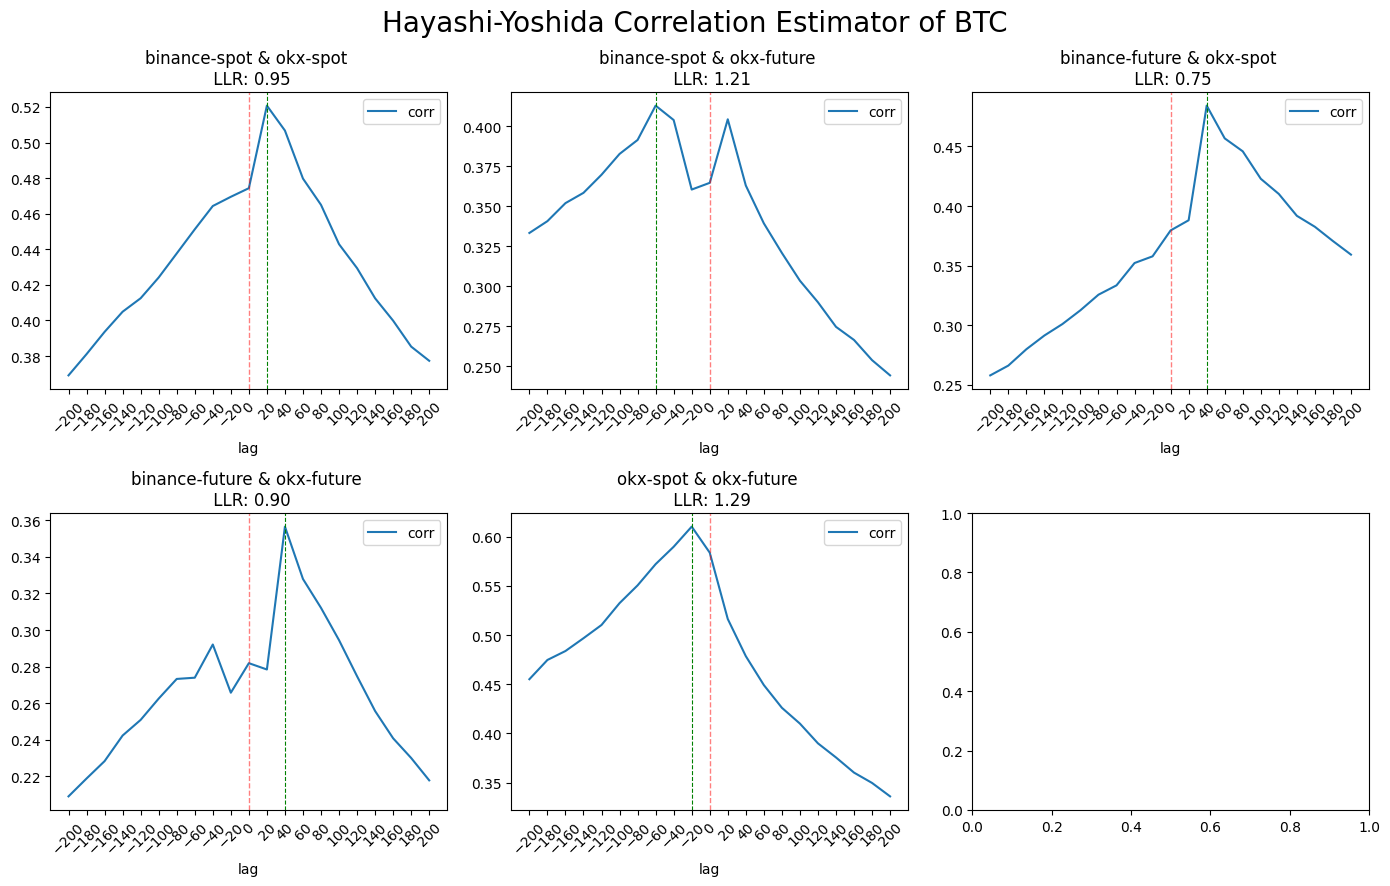

In [22]:
draw_hycorr("BTC")